# Statistics

In [40]:
import numpy as np
import pandas as pd#
import os

ROOT = "data/textClust_stream_data"

def load_data_statisitcs(dataset_file_name):
    stats_file = f"{ROOT}/raw_data/{dataset_file_name}"
    if stats_file.endswith('.json'):
        stats_df = pd.read_json(stats_file, lines=True)
        stats_df = stats_df.rename(columns = {"topic":"clusterNo"})
    elif stats_file.endswith('.npy'):
        ds = np.load(stats_file, allow_pickle=True)
        tweetIDs = ds[:, 0]
        clusterNo = ds[:, 2]
        ds = {
            "tweetID": tweetIDs,
            "clusterNo": clusterNo
        }
        stats_df = pd.DataFrame(ds)
    else:
        print(f"Unsupported file format for {stats_file}. Please provide a .json or .npy file.")
        return None
    
    num_samples = stats_df["tweetID"].unique().shape[0]
    num_clusters = stats_df["clusterNo"].unique().shape[0]
    avg_cluster_size = stats_df.groupby("clusterNo").size().mean()
    std_cluster_size = stats_df.groupby("clusterNo").size().std()
    min_cluster_size = stats_df.groupby("clusterNo").size().min()
    max_cluster_size = stats_df.groupby("clusterNo").size().max()
    cluster_entropy = stats_df.groupby("clusterNo").size().apply(lambda x: -x/num_samples * np.log2(x/num_samples)).sum()
    stats = {
        "dataset": dataset_file_name,
        "num_samples": num_samples,
        "num_clusters": num_clusters,
        "avg_cluster_size": avg_cluster_size,
        "std_cluster_size": std_cluster_size,
        "min_cluster_size": min_cluster_size,
        "max_cluster_size": max_cluster_size,
        "cluster_entropy": cluster_entropy
    }
    return pd.DataFrame([stats])

result = pd.concat([load_data_statisitcs(file) for file in os.listdir(f"{ROOT}/raw_data")])

Unsupported file format for data/textClust_stream_data/raw_data/.DS_Store. Please provide a .json or .npy file.
Unsupported file format for data/textClust_stream_data/raw_data/.gitkeep. Please provide a .json or .npy file.


In [41]:
result

,dataset,num_samples,num_clusters,avg_cluster_size,std_cluster_size,min_cluster_size,max_cluster_size,cluster_entropy
0,NT.json,41429,419,98.875895,139.490456,1,1558,7.873578
0,KBP.npy,85569,100,855.690000,3338.392508,2,26299,3.735352
0,Event2012.npy,68841,503,136.860835,397.019865,1,7133,7.548635
0,CrisisLexT26.npy,27932,26,1074.346154,129.510754,1000,1442,4.691071
0,Event2012_100.npy,15019,100,150.190000,272.131270,55,2377,5.761623
0,Semantic5-T_sorted.json,50000,5,10000.000000,0.000000,10000,10000,2.321928
0,NTSO-T.json,104135,10994,9.471985,20.585878,1,1035,12.725985
0,Arabic_Twitter.npy,9070,7,1295.714286,783.649095,519,2883,2.606203
0,Mix_Data.npy,75960,5,15192.000000,19671.562406,2292,49538,1.514479
0,Semantic10-T.json,25576,10,2557.600000,622.375235,1510,3756,3.283558


# Loading the results

In [92]:
import pandas as pd
import matplotlib.pyplot as plt 
import numpy as np
import seaborn as sns
import os
import json
import ast # For converting string representation of list to actual list

In [43]:
%pwd

'/Users/lms/Documents/Forschung/textClust_hpo'

## Loading the performances of found configurations

In [124]:
dfs = []

root = "results/textClust_hpo_results/smac3_final_performance"

for file in os.listdir(f"{root}/embClust"):
    df = pd.read_csv(os.path.join(f"{root}/embClust", file))
    dfs.append(df)

for file in os.listdir(f"{root}/textClust"):
    df = pd.read_csv(os.path.join(f"{root}/textClust", file))
    dfs.append(df)
    
for file in os.listdir(f"{root}/inc_clust_ray"):
    df = pd.read_csv(os.path.join(f"{root}/inc_clust_ray", file))
    dfs.append(df)
        
smac3_results_eval = pd.concat(dfs, ignore_index=True)

# Rename the dataset column to remove the file destination and suffix from the dataset names.
smac3_results_eval["dataset"] = (
    smac3_results_eval["dataset"]
    .str.replace("data/textClust_stream_data/raw_data/", "", regex=False)
    .str.replace(".npy", "", regex=False)
    .str.replace(".json", "", regex=False)
    .str.replace("data/raw_data/", "")
)



# Parse and expand strings such as "['Arabic_Twitter', 'Semantic40-T']" inline.
smac3_results_eval[["loo_dataset_1", "loo_dataset_2"]] = (
    smac3_results_eval["loo_datasets"]
    .apply(lambda value: value.replace("['", "").replace("']", "").split(" ") if value.startswith('[') else (None,None))
    .apply(pd.Series)
    )
# Optional: mark rows whose evaluated dataset is one of the held-out datasets.
smac3_results_eval["is_test"] = smac3_results_eval.apply(
    lambda row: row["dataset"] in {
        row["loo_dataset_1"],
        row["loo_dataset_2"],
    },
    axis=1,
)

display(smac3_results_eval[["dataset", "loo_datasets", "loo_dataset_1", "loo_dataset_2", "is_test"]].head(10))

# Rename inc_clust_ray to FSD 
smac3_results_eval["algorithm"] = smac3_results_eval["algorithm"].replace({"inc_clust_ray": "FSD"})
smac3_results_eval = smac3_results_eval.rename(columns={"config_id": "config_index"})
smac3_results_eval["config_source"] = "cv"
smac3_results_eval.loc[smac3_results_eval["loo_datasets"] == "none", "config_source"] = "full"

smac3_results_eval["config_id"] = smac3_results_eval.apply(
    lambda row: f"{row['algorithm']}_{row['config']}[{row['config_index']}]",
    axis=1
)

display(smac3_results_eval)

,dataset,loo_datasets,loo_dataset_1,loo_dataset_2,is_test
0,Arabic_7,['CrisisNLP CrisisMMD'],CrisisNLP,CrisisMMD,False
1,Arabic_Twitter,['CrisisNLP CrisisMMD'],CrisisNLP,CrisisMMD,False
2,CrisisLexT6,['CrisisNLP CrisisMMD'],CrisisNLP,CrisisMMD,False
3,CrisisLexT7,['CrisisNLP CrisisMMD'],CrisisNLP,CrisisMMD,False
4,CrisisLexT26,['CrisisNLP CrisisMMD'],CrisisNLP,CrisisMMD,False
5,CrisisMMD,['CrisisNLP CrisisMMD'],CrisisNLP,CrisisMMD,True
6,CrisisNLP,['CrisisNLP CrisisMMD'],CrisisNLP,CrisisMMD,True
7,Event2012,['CrisisNLP CrisisMMD'],CrisisNLP,CrisisMMD,False
8,Event2018,['CrisisNLP CrisisMMD'],CrisisNLP,CrisisMMD,False
9,HumAID,['CrisisNLP CrisisMMD'],CrisisNLP,CrisisMMD,False


,rand,adj_rand,mutual_info,adj_mutual_info,normalized_mutual_info,homogeneity,completeness,v_measure,fowlkes_mallows,rand_final,...,config,config_index,loo_datasets,seed,algorithm,loo_dataset_1,loo_dataset_2,is_test,config_source,config_id
0,0.844753,0.391958,1.277819,0.588289,0.592668,0.707404,0.509957,0.592668,0.493394,0.509297,...,best_config_loo_['CrisisNLP CrisisMMD']_seed_1...,0,['CrisisNLP CrisisMMD'],10,embClust,CrisisNLP,CrisisMMD,False,cv,embClust_best_config_loo_['CrisisNLP CrisisMMD...
1,0.803760,0.287625,1.224263,0.533307,0.536971,0.677705,0.444636,0.536971,0.406322,0.381172,...,best_config_loo_['CrisisNLP CrisisMMD']_seed_1...,0,['CrisisNLP CrisisMMD'],10,embClust,CrisisNLP,CrisisMMD,False,cv,embClust_best_config_loo_['CrisisNLP CrisisMMD...
2,0.751099,0.057528,1.077236,0.354579,0.362992,0.601217,0.259979,0.362992,0.204742,0.191750,...,best_config_loo_['CrisisNLP CrisisMMD']_seed_1...,0,['CrisisNLP CrisisMMD'],10,embClust,CrisisNLP,CrisisMMD,False,cv,embClust_best_config_loo_['CrisisNLP CrisisMMD...
3,0.784356,0.466458,0.894267,0.540423,0.547149,0.669018,0.462838,0.547149,0.621881,0.848239,...,best_config_loo_['CrisisNLP CrisisMMD']_seed_1...,0,['CrisisNLP CrisisMMD'],10,embClust,CrisisNLP,CrisisMMD,False,cv,embClust_best_config_loo_['CrisisNLP CrisisMMD...
4,0.941662,0.347911,2.505017,0.727979,0.731640,0.770415,0.696581,0.731640,0.383085,0.131940,...,best_config_loo_['CrisisNLP CrisisMMD']_seed_1...,0,['CrisisNLP CrisisMMD'],10,embClust,CrisisNLP,CrisisMMD,False,cv,embClust_best_config_loo_['CrisisNLP CrisisMMD...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22795,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.983797,...,best_config_loo_['Semantic5-T CrisisLexT7']_se...,7,['Semantic5-T CrisisLexT7'],2,FSD,Semantic5-T,CrisisLexT7,False,cv,FSD_best_config_loo_['Semantic5-T CrisisLexT7'...
22796,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.576707,...,best_config_loo_['Semantic5-T CrisisLexT7']_se...,7,['Semantic5-T CrisisLexT7'],2,FSD,Semantic5-T,CrisisLexT7,False,cv,FSD_best_config_loo_['Semantic5-T CrisisLexT7'...
22797,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.765189,...,best_config_loo_['Semantic5-T CrisisLexT7']_se...,7,['Semantic5-T CrisisLexT7'],2,FSD,Semantic5-T,CrisisLexT7,True,cv,FSD_best_config_loo_['Semantic5-T CrisisLexT7'...
22798,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.898442,...,best_config_loo_['Semantic5-T CrisisLexT7']_se...,7,['Semantic5-T CrisisLexT7'],2,FSD,Semantic5-T,CrisisLexT7,False,cv,FSD_best_config_loo_['Semantic5-T CrisisLexT7'...


In [94]:
smac3_results_eval["config_id"][0]

"embClust_best_config_loo_['Semantic5-T', 'CrisisLexT7']_seed_1.json[0]"

In [125]:
# Read configurations
root = "results/textClust_hpo_results/smac3_best_configs"

def load_configurations(algorithm):
    config_dir = os.path.join(root, algorithm)
    results = []
    display_algorithm = "FSD" if algorithm == "inc_clust_ray" else algorithm

    for file in os.listdir(config_dir):
        if not file.endswith(".json"):
            continue

        config_path = os.path.join(config_dir, file)
        with open(config_path, "r") as config_file:
            config = pd.DataFrame(json.load(config_file))

        config["algorithm"] = display_algorithm
        config["config"] = file
        config = config.reset_index(names=["config_index"])
        config["config_id"] = config.apply(
            lambda row: f"{row['algorithm']}_{row['config']}[{row['config_index']}]",
            axis=1
        )
        results.append(config)

    return pd.concat(results, ignore_index=True)

smac3_configs = pd.concat([
    load_configurations("embClust"),
    load_configurations("textClust"),
    load_configurations("inc_clust_ray")
], ignore_index=True)

display(smac3_configs)

,config_index,adaptive_threshold,clean_interval,cluster_interval,decay_rate,min_num_mc,model,use_heuristic,min_weight,radius,time_gap,algorithm,config,config_id,sigma,threshold_momentum,term_fading,batch_size,threshold,window
0,0,0.0,48.0,3649.0,0.008297,22.0,minishlab_32M,0.0,1.843183,0.300000,NaN,embClust,best_config_loo_['CrisisNLP CrisisMMD']_seed_6...,embClust_best_config_loo_['CrisisNLP CrisisMMD...,NaN,NaN,NaN,NaN,NaN,NaN
1,1,0.0,466.0,3388.0,0.000323,28.0,minishlab_2M,1.0,NaN,0.750472,526.036785,embClust,best_config_loo_['CrisisNLP CrisisMMD']_seed_6...,embClust_best_config_loo_['CrisisNLP CrisisMMD...,NaN,NaN,NaN,NaN,NaN,NaN
2,2,0.0,117.0,3798.0,0.000344,28.0,sentence_transformers_all_MiniLM_L6_v2,1.0,NaN,0.536648,3092.097202,embClust,best_config_loo_['CrisisNLP CrisisMMD']_seed_6...,embClust_best_config_loo_['CrisisNLP CrisisMMD...,NaN,NaN,NaN,NaN,NaN,NaN
3,3,0.0,387.0,3216.0,0.000143,24.0,minishlab_32M,0.0,0.035287,0.783909,NaN,embClust,best_config_loo_['CrisisNLP CrisisMMD']_seed_6...,embClust_best_config_loo_['CrisisNLP CrisisMMD...,NaN,NaN,NaN,NaN,NaN,NaN
4,4,0.0,32.0,3223.0,0.000133,29.0,minishlab_8M,1.0,NaN,0.789252,3976.251356,embClust,best_config_loo_['CrisisNLP CrisisMMD']_seed_6...,embClust_best_config_loo_['CrisisNLP CrisisMMD...,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1420,2,NaN,NaN,NaN,NaN,NaN,minishlab_2M,NaN,NaN,NaN,NaN,FSD,best_config_loo_['MAVEN HumAID']_seed_2.json,FSD_best_config_loo_['MAVEN HumAID']_seed_2.js...,NaN,NaN,NaN,23.0,0.754823,93.0
1421,3,NaN,NaN,NaN,NaN,NaN,minishlab_2M,NaN,NaN,NaN,NaN,FSD,best_config_loo_['MAVEN HumAID']_seed_2.json,FSD_best_config_loo_['MAVEN HumAID']_seed_2.js...,NaN,NaN,NaN,7.0,0.473443,117.0
1422,4,NaN,NaN,NaN,NaN,NaN,minishlab_8M,NaN,NaN,NaN,NaN,FSD,best_config_loo_['MAVEN HumAID']_seed_2.json,FSD_best_config_loo_['MAVEN HumAID']_seed_2.js...,NaN,NaN,NaN,8.0,0.539958,125.0
1423,5,NaN,NaN,NaN,NaN,NaN,minishlab_8M,NaN,NaN,NaN,NaN,FSD,best_config_loo_['MAVEN HumAID']_seed_2.json,FSD_best_config_loo_['MAVEN HumAID']_seed_2.js...,NaN,NaN,NaN,8.0,0.556623,125.0


In [126]:
# Merge the configurations with the evaluation results on the config_id column.
d = smac3_results_eval.copy()
d = d.merge(smac3_configs, how="outer", indicator=True)

assert d["_merge"].value_counts().get("both", 0) == len(smac3_results_eval), "Not all evaluation results have a matching configuration."

d = d.drop(columns=["_merge"])
smac3_results_eval = d
smac3_results_eval.head()

,rand,adj_rand,mutual_info,adj_mutual_info,normalized_mutual_info,homogeneity,completeness,v_measure,fowlkes_mallows,rand_final,...,use_heuristic,min_weight,radius,time_gap,sigma,threshold_momentum,term_fading,batch_size,threshold,window
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.800478,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.0,0.5,125.0
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.825940,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.0,0.5,125.0
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.841990,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.0,0.5,125.0
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.679593,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.0,0.5,125.0
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.961139,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.0,0.5,125.0


## Loading the performance of the default configurations

In [48]:
root_performance = "results/textClust_hpo_results/default_on_all_datasets"
root_configs = "smac_hpo/defaults"

def load() -> pd.DataFrame:
    results = []
    for file in os.listdir(f"{root_configs}"):
        df = pd.read_json(os.path.join(f"{root_configs}", file), lines=False)
        algorithm = ""
        if "embClust" in file:
            algorithm = "embClust"
        elif "textClust" in file:
            algorithm = "textClust"
        elif "inc_clust_ray" in file:
            algorithm = "FSD"
        df["config_id"] = f"{algorithm}_{file}"
        df["algorithm"] = algorithm
        df["config"] = file
        performance = pd.read_csv(os.path.join(f"{root_performance}", f"smac_hpo_defaults_{file}_results.csv"))
        performance["config_id"] = f"{algorithm}_{file}"
        performance["algorithm"] = algorithm
        performance["config"] = file
        performance = performance.drop(columns=["dataset"])
        performance = performance.rename(columns={"dataset_name": "dataset"})
        df = df.merge(performance, on=["config_id", "algorithm", "config"], how="outer", indicator=True)
        assert df["_merge"].value_counts().get("both", 0) == len(performance), "Not all performance results have a matching configuration."
        df = df.drop(columns=["_merge"])
        results.append(df)
    return pd.concat(results, ignore_index=True)

default_performances = load()
default_performances["config_source"] = "default"
default_performances.head()

,clean_interval,cluster_interval,decay_rate,min_num_mc,adaptive_threshold,radius,threshold_momentum,use_heuristic,time_gap,model,...,avg_throughput,total_time,dataset,config_index,term_fading,sigma,threshold,window,batch_size,config_source
0,392.0,392.0,0.7682,1.0,0.0,0.3593,0.0,1.0,392.0,sentence_transformers_all_MiniLM_L6_v2,...,2.036198,1484.138224,Arabic_7,0,NaN,NaN,NaN,NaN,NaN,default
1,392.0,392.0,0.7682,1.0,0.0,0.3593,0.0,1.0,392.0,sentence_transformers_all_MiniLM_L6_v2,...,184.680105,49.111950,Arabic_Twitter,0,NaN,NaN,NaN,NaN,NaN,default
2,392.0,392.0,0.7682,1.0,0.0,0.3593,0.0,1.0,392.0,sentence_transformers_all_MiniLM_L6_v2,...,172.178211,348.929168,CrisisLexT6,0,NaN,NaN,NaN,NaN,NaN,default
3,392.0,392.0,0.7682,1.0,0.0,0.3593,0.0,1.0,392.0,sentence_transformers_all_MiniLM_L6_v2,...,186.605356,10.498091,CrisisLexT7,0,NaN,NaN,NaN,NaN,NaN,default
4,392.0,392.0,0.7682,1.0,0.0,0.3593,0.0,1.0,392.0,sentence_transformers_all_MiniLM_L6_v2,...,173.470768,161.012719,CrisisLexT26,0,NaN,NaN,NaN,NaN,NaN,default


In [49]:
smac3_results_eval = pd.concat([smac3_results_eval, default_performances], ignore_index=True)

# Loading the results of the on the old datasets

In [50]:
# TODO
old_datasets = [ "News-T", "NT", "NTS", "NTSO", "SO-T", "Trends-T", "Tweets-T" ]
smac3_results_full["is_old"] = False
smac3_results_full.loc[smac3_results_full["dataset"].isin(old_datasets), "is_old"] = True

NameError: name 'smac3_results_full' is not defined

## Loading configurations and merge into results

In [ ]:
root = "results/textClust_hpo_results/cross_validation/smac3_best_configs"

def read_config(algorithm: str) -> pd.DataFrame:
    result = []
    for file in os.listdir(f"{root}/{algorithm}"):
        if file.endswith(".json"):
            f = file.replace(".json", "")
            loo_datasets = f.split("_seed_")[0].replace(f"best_config_loo_", "")
            seed = int(f.split("_")[-1])
            ds1, ds2 = ast.literal_eval(loo_datasets)
            with open(os.path.join(f"{root}/{algorithm}", file), "r") as f:
                config = json.load(f)
                df = pd.DataFrame(config)
                df = df.reset_index(names=["config_id"])
                df["config"]=file.replace(".json", "")
                df["algorithm"] = algorithm.replace("inc_clust_ray", "FSD")
                df["loo_datasets"] = loo_datasets
                df["loo_dataset_1"] = ds1
                df["loo_dataset_2"] = ds2
                df["seed"] = seed
                result.append(df)
    return pd.concat(result, ignore_index=True)

algorithms = ["embClust", "textClust", "inc_clust_ray"]

smac3_results_config = pd.concat([read_config(algorithm) for algorithm in algorithms])
smac3_results_config.head()

,config_id,adaptive_threshold,clean_interval,cluster_interval,decay_rate,min_num_mc,model,use_heuristic,min_weight,radius,...,threshold_momentum,config,algorithm,loo_datasets,loo_dataset_1,loo_dataset_2,seed,batch_size,threshold,window
0,0,0.0,48.0,3649.0,0.008297,22.0,minishlab_32M,0.0,1.843183,0.30000,...,NaN,"best_config_loo_['Semantic10-T', 'Event2018']_...",embClust,"['Semantic10-T', 'Event2018']",Semantic10-T,Event2018,6,NaN,NaN,NaN
1,1,0.0,424.0,3567.0,0.000614,16.0,minishlab_4M,1.0,NaN,0.63255,...,NaN,"best_config_loo_['Semantic10-T', 'Event2018']_...",embClust,"['Semantic10-T', 'Event2018']",Semantic10-T,Event2018,6,NaN,NaN,NaN
2,2,1.0,424.0,3484.0,0.000712,18.0,sentence_transformers_all_MiniLM_L6_v2,1.0,NaN,NaN,...,0.268146,"best_config_loo_['Semantic10-T', 'Event2018']_...",embClust,"['Semantic10-T', 'Event2018']",Semantic10-T,Event2018,6,NaN,NaN,NaN
3,3,1.0,413.0,3484.0,0.000628,19.0,minishlab_32M,1.0,NaN,NaN,...,0.427894,"best_config_loo_['Semantic10-T', 'Event2018']_...",embClust,"['Semantic10-T', 'Event2018']",Semantic10-T,Event2018,6,NaN,NaN,NaN
4,0,1.0,240.0,160.0,0.000151,28.0,minishlab_32M,1.0,NaN,NaN,...,0.449300,"best_config_loo_['Mix_Data', 'CrisisLexT6']_se...",embClust,"['Mix_Data', 'CrisisLexT6']",Mix_Data,CrisisLexT6,7,NaN,NaN,NaN


In [ ]:
print(f"len(smac3_results_eval): {len(smac3_results_eval)}")
print(f"len(smac3_results_config): {len(smac3_results_config)}")

smac3_results_config.loc[:,"config_hash"] = smac3_results_config[["algorithm", "config_id", "loo_datasets", "seed", "config"]].apply(
    lambda row: hash(frozenset(row.items())), axis=1
)

smac3_results = smac3_results_eval.merge(
    smac3_results_config,
    on=["algorithm", "config_id", "loo_datasets", "seed", "loo_dataset_1", "loo_dataset_2"],
    how="left",
    indicator=True
)

missing_mask = ~smac3_results["is_default"] & (smac3_results["_merge"] == "left_only")

assert not missing_mask.any(), "Some rows (except default) did not match during the merge."
print(f"len(smac3_results): {len(smac3_results)}")
print (smac3_results.columns)
smac3_results.head()

len(smac3_results_eval): 19813
len(smac3_results_config): 1234
len(smac3_results): 19813
Index(['rand', 'adj_rand', 'mutual_info', 'adj_mutual_info',
       'normalized_mutual_info', 'homogeneity', 'completeness', 'v_measure',
       'fowlkes_mallows', 'rand_final', 'adj_rand_final', 'mutual_info_final',
       'adj_mutual_info_final', 'normalized_mutual_info_final',
       'homogeneity_final', 'completeness_final', 'v_measure_final',
       'fowlkes_mallows_final', 'num_evaluated_points', 'num_clusters_initial',
       'num_clusters_final', 'num_clusters_true', 'avg_throughput',
       'total_time', 'dataset', 'config_x', 'config_id', 'loo_datasets',
       'seed', 'algorithm', 'loo_dataset_1', 'loo_dataset_2', 'is_test',
       'is_default', 'adaptive_threshold', 'clean_interval',
       'cluster_interval', 'decay_rate', 'min_num_mc', 'model',
       'use_heuristic', 'min_weight', 'radius', 'time_gap', 'sigma',
       'threshold_momentum', 'config_y', 'batch_size', 'threshold', 'wind

,rand,adj_rand,mutual_info,adj_mutual_info,normalized_mutual_info,homogeneity,completeness,v_measure,fowlkes_mallows,rand_final,...,radius,time_gap,sigma,threshold_momentum,config_y,batch_size,threshold,window,config_hash,_merge
0,0.833070,0.180472,1.569423,0.483905,0.516631,0.868837,0.367610,0.516631,0.333087,0.833070,...,NaN,NaN,0.707154,0.706948,"best_config_loo_['Semantic5-T', 'CrisisLexT7']...",NaN,NaN,NaN,4.900234e+18,both
1,0.822396,0.087991,1.682569,0.441246,0.471804,0.931406,0.315915,0.471804,0.230966,0.822396,...,NaN,NaN,0.707154,0.706948,"best_config_loo_['Semantic5-T', 'CrisisLexT7']...",NaN,NaN,NaN,4.900234e+18,both
2,0.835575,0.026425,1.719764,0.368125,0.393626,0.959819,0.247580,0.393626,0.118039,0.835595,...,NaN,NaN,0.707154,0.706948,"best_config_loo_['Semantic5-T', 'CrisisLexT7']...",NaN,NaN,NaN,4.900234e+18,both
3,0.706331,0.176099,1.155964,0.423170,0.458386,0.864798,0.311838,0.458386,0.367659,0.706331,...,NaN,NaN,0.707154,0.706948,"best_config_loo_['Semantic5-T', 'CrisisLexT7']...",NaN,NaN,NaN,4.900234e+18,both
4,0.966082,0.235662,3.156235,0.631975,0.672333,0.970696,0.514264,0.672333,0.360920,0.966172,...,NaN,NaN,0.707154,0.706948,"best_config_loo_['Semantic5-T', 'CrisisLexT7']...",NaN,NaN,NaN,4.900234e+18,both


## Helper functions

In [97]:
def pareto_optimal_points(
    data: pd.DataFrame,
    objective_columns: list[str],
    maximize: bool | list[bool] = False,
) -> tuple[pd.Index, pd.DataFrame]:
    """Return the indices and objective values of Pareto-optimal rows.

    Parameters
    ----------
    data:
        DataFrame containing the objective columns.
    objective_columns:
        Column names used as objectives.
    maximize:
        Either one boolean applied to every objective or one boolean per
        objective. ``True`` means maximize that objective; ``False`` means
        minimize it. The default minimizes all objectives.

    Returns
    -------
    tuple[pd.Index, pd.DataFrame]
        The original DataFrame indices and a DataFrame containing the
        corresponding objective values.
    """
    if not objective_columns:
        raise ValueError("objective_columns must contain at least one column")

    missing_columns = [
        column for column in objective_columns if column not in data.columns
    ]
    if missing_columns:
        raise KeyError(f"Objective columns not found: {missing_columns}")

    if isinstance(maximize, bool):
        maximize = [maximize] * len(objective_columns)
    else:
        maximize = list(maximize)
        if len(maximize) != len(objective_columns):
            raise ValueError(
                "maximize must be a bool or have one value per objective column"
            )
        if not all(isinstance(value, bool) for value in maximize):
            raise TypeError("maximize must contain only booleans")

    objectives = data.loc[:, objective_columns]
    if objectives.isna().any().any():
        raise ValueError("Objective values must not contain missing values")

    # Convert all objectives to maximization objectives. A row dominates
    # another when it is at least as good in every objective and better in one.
    values = objectives.to_numpy(dtype=float)
    transformed = values.copy()
    for column_index, should_maximize in enumerate(maximize):
        if not should_maximize:
            transformed[:, column_index] *= -1

    dominates = (
        (transformed[:, None, :] >= transformed[None, :, :]).all(axis=2)
        & (transformed[:, None, :] > transformed[None, :, :]).any(axis=2)
    )
    pareto_mask = ~dominates.any(axis=0)

    pareto_indices = data.index[pareto_mask]
    pareto_objectives = objectives.loc[pareto_indices]
    return pareto_indices, pareto_objectives

In [98]:
def normalize(df: pd.DataFrame, columns: list[str], use_log: list[bool] | bool = False) -> pd.DataFrame:
    """Normalize the specified columns of a DataFrame to the range [0, 1].

    Parameters
    ----------
    df:
        DataFrame containing the columns to normalize.
    columns:
        List of column names to normalize.
    use_log:
        Either one boolean applied to every column or one boolean per
        column. ``True`` means apply log transformation before normalization.
        
    Returns
    -------
    pd.DataFrame
        DataFrame with the specified columns normalized to the range [0, 1].    
    """
    if isinstance(use_log, bool):
        use_log = [use_log] * len(columns)
    else:
        use_log = list(use_log)
        if len(use_log) != len(columns):
            raise ValueError(
                "use_log must be a bool or have one value per column"
            )
        if not all(isinstance(value, bool) for value in use_log):
            raise TypeError("use_log must contain only booleans")

    df_normalized = df.copy()
    for column, log_transform in zip(columns, use_log):
        if log_transform:
            df_normalized[column] = np.log1p(df_normalized[column])
        min_value = 0.0
        max_value = df_normalized[column].max()
        df_normalized[column] = (df_normalized[column] - min_value) / (max_value - min_value)

    return df_normalized

In [99]:
color_palette = sns.color_palette("Paired", n_colors=3)

colors = {
    "FSD": color_palette[2],
    "embClust": color_palette[1],
    "textClust": color_palette[0],
}

order = list(colors.keys())

# Normalize

In [100]:
smac3_results_eval

,rand,adj_rand,mutual_info,adj_mutual_info,normalized_mutual_info,homogeneity,completeness,v_measure,fowlkes_mallows,rand_final,...,model,use_heuristic,min_weight,radius,time_gap,sigma,threshold_momentum,batch_size,threshold,window
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.825084,...,sentence_transformers_all_MiniLM_L6_v2,NaN,NaN,NaN,NaN,NaN,NaN,8.0,0.55,24.0
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.867341,...,sentence_transformers_all_MiniLM_L6_v2,NaN,NaN,NaN,NaN,NaN,NaN,8.0,0.55,24.0
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.703828,...,sentence_transformers_all_MiniLM_L6_v2,NaN,NaN,NaN,NaN,NaN,NaN,8.0,0.55,24.0
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.837393,...,sentence_transformers_all_MiniLM_L6_v2,NaN,NaN,NaN,NaN,NaN,NaN,8.0,0.55,24.0
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.982507,...,sentence_transformers_all_MiniLM_L6_v2,NaN,NaN,NaN,NaN,NaN,NaN,8.0,0.55,24.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15387,0.855311,0.005802,1.268478,0.057824,0.288911,0.281880,0.296301,0.288911,0.055083,0.071208,...,NaN,1.0,NaN,NaN,107.651671,0.135389,0.297403,NaN,NaN,NaN
15388,0.773266,0.439738,0.264201,0.400129,0.403054,0.978929,0.253769,0.403054,0.857910,0.808028,...,NaN,1.0,NaN,NaN,107.651671,0.135389,0.297403,NaN,NaN,NaN
15389,0.793421,0.232652,1.147413,0.497256,0.497969,0.760165,0.370259,0.497969,0.390243,0.793600,...,NaN,1.0,NaN,NaN,107.651671,0.135389,0.297403,NaN,NaN,NaN
15390,0.882005,0.139963,1.277303,0.377958,0.390442,0.561208,0.299354,0.390442,0.212417,0.151160,...,NaN,1.0,NaN,NaN,107.651671,0.135389,0.297403,NaN,NaN,NaN


In [116]:
df = smac3_results_eval.copy()

# Normalize per dataset
for _, group in df.groupby(["dataset"]):
    df.loc[group.index, ["avg_throughput_normalized", "adj_mutual_info_final_normalized"]] = normalize(group, columns=["avg_throughput", "adj_mutual_info_final"], use_log=[True, False])[["avg_throughput", "adj_mutual_info_final"]]

smac3_results_eval = df

# Check generalizability

In [127]:
smac3_results_eval["config_id"][0]

"FSD_best_config_loo_['Arabic_Twitter Semantic40-T']_seed_1.json[0]"

In [128]:
smac3_results_eval.columns

Index(['rand', 'adj_rand', 'mutual_info', 'adj_mutual_info',
       'normalized_mutual_info', 'homogeneity', 'completeness', 'v_measure',
       'fowlkes_mallows', 'rand_final', 'adj_rand_final', 'mutual_info_final',
       'adj_mutual_info_final', 'normalized_mutual_info_final',
       'homogeneity_final', 'completeness_final', 'v_measure_final',
       'fowlkes_mallows_final', 'num_evaluated_points', 'num_clusters_initial',
       'num_clusters_final', 'num_clusters_true', 'avg_throughput',
       'total_time', 'dataset', 'config', 'config_index', 'loo_datasets',
       'seed', 'algorithm', 'loo_dataset_1', 'loo_dataset_2', 'is_test',
       'config_source', 'config_id', 'adaptive_threshold', 'clean_interval',
       'cluster_interval', 'decay_rate', 'min_num_mc', 'model',
       'use_heuristic', 'min_weight', 'radius', 'time_gap', 'sigma',
       'threshold_momentum', 'term_fading', 'batch_size', 'threshold',
       'window'],
      dtype='str')

In [129]:
smac3_results_eval[smac3_results_eval["config_source"] == "full"].groupby(["dataset"])[["avg_throughput", "adj_mutual_info_final"]].max()


,avg_throughput,adj_mutual_info_final
dataset,,
Arabic_7,1744.309932,0.656498
Arabic_Twitter,1853.089038,0.673749
CrisisLexT26,1768.844741,0.887266
CrisisLexT6,2417.227030,0.520040
CrisisLexT7,2771.727325,0.702305
CrisisMMD,2942.257267,0.734470
CrisisNLP,1937.233496,0.629759
Event2012,2468.485350,0.878050
Event2018,1772.039173,0.817998


In [130]:
from moocore import hypervolume

df = smac3_results_eval.copy()
df = df[df["config_source"] == "cv"]

# Normalize per dataset
for _, group in df.groupby(["dataset"]):
    df.loc[group.index, ["avg_throughput", "adj_mutual_info_final"]] = normalize(group, columns=["avg_throughput", "adj_mutual_info_final"], use_log=[True, False])[["avg_throughput", "adj_mutual_info_final"]]

results_hv = []

for (algorithm, ds), group in df.groupby(["algorithm", "dataset"]):
    test_group = group[group["is_test"] == True]
    if len(test_group) == 0:
        continue
    
    hv_test = hypervolume(test_group[["avg_throughput", "adj_mutual_info_final"]].values, ref=[0.0, 0.0], maximise=[True, True])
    ami_test = test_group["adj_mutual_info_final"].max()
    throughput_test = test_group["avg_throughput"].max()
    
    train_group = group[group["is_test"] == False]
    for _, group in train_group.groupby(["loo_dataset_1", "loo_dataset_2"]):
        
        hv_train = hypervolume(group[["avg_throughput", "adj_mutual_info_final"]].values, ref=[0.0, 0.0], maximise=[True, True])
        ami_train = group["adj_mutual_info_final"].max()
        throughput_train = group["avg_throughput"].max()
        results_hv.append({
            "algorithm": algorithm,
            "loo_datasets": f"[{group['loo_dataset_1'].iloc[0]}, {group['loo_dataset_2'].iloc[0]}]",
            "dataset": ds,
            "hv_train": hv_train,
            "hv_test": hv_test,
            "hv_ratio": hv_test / hv_train if hv_train > 0 else np.nan,
            "ami_train": ami_train,
            "ami_test": ami_test,
            "ami_ratio": ami_test / ami_train if ami_train > 0 else np.nan,
            "throughput_train": throughput_train,
            "throughput_test": throughput_test,
            "throughput_ratio": throughput_test / throughput_train if throughput_train > 0 else np.nan
        })

df_results_hv = pd.DataFrame(results_hv)
df_results_hv.head()
#df = df_results_hv.copy()
# df = df.pivot_table(index=["algorithm"], columns="dataset", values=["hv_ratio", "hv_train", "hv_test"])
# #  Add mean and std columns
# #df["mean"] = df.mean(axis=1)
# #df["std"] = df.std(axis=1)   
# df["hv_train_mean"] = df["hv_train"].mean(axis=1)
# df["hv_train_std"] = df["hv_train"].std(axis=1)
# df["hv_test_mean"] = df["hv_test"].mean(axis=1)
# df["hv_test_std"] = df["hv_test"].std(axis=1)
# df["hv_ratio_mean"] = df["hv_ratio"].mean(axis=1)
# df["hv_ratio_std"] = df["hv_ratio"].std(axis=1)
# df 


,algorithm,loo_datasets,dataset,hv_train,hv_test,hv_ratio,ami_train,ami_test,ami_ratio,throughput_train,throughput_test,throughput_ratio
0,FSD,"[Arabic_Twitter, Semantic40-T]",Arabic_7,0.548834,0.828511,1.509584,0.629709,0.883711,1.403365,0.963781,0.967251,1.003600
1,FSD,"[CrisisNLP, CrisisMMD]",Arabic_7,0.666752,0.828511,1.242608,0.711383,0.883711,1.242244,0.967201,0.967251,1.000051
2,FSD,"[Event2012, CrisisLexT26]",Arabic_7,0.909611,0.828511,0.910842,0.977364,0.883711,0.904178,0.967682,0.967251,0.999554
3,FSD,"[MAVEN, HumAID]",Arabic_7,0.720579,0.828511,1.149785,0.762705,0.883711,1.158653,0.965278,0.967251,1.002044
4,FSD,"[Mix_Data, CrisisLexT6]",Arabic_7,0.552982,0.828511,1.498261,0.724998,0.883711,1.218915,0.966633,0.967251,1.000639


In [131]:
df_results_hv[(df_results_hv["algorithm"] != "embCluste") & (df_results_hv["dataset"] == "CrisisMMD")].sort_values(by="algorithm", ascending=False)

,algorithm,loo_datasets,dataset,hv_train,hv_test,hv_ratio,ami_train,ami_test,ami_ratio,throughput_train,throughput_test,throughput_ratio
265,textClust,"[Semantic5-T, CrisisLexT7]",CrisisMMD,0.889181,0.878354,0.987823,0.950459,0.952026,1.001649,0.967095,0.949989,0.982312
264,textClust,"[Semantic10-T, Event2018]",CrisisMMD,0.884404,0.878354,0.993159,0.956755,0.952026,0.995057,0.970236,0.949989,0.979132
263,textClust,"[Mix_Data, CrisisLexT6]",CrisisMMD,0.876050,0.878354,1.002630,0.961985,0.952026,0.989647,0.957908,0.949989,0.991733
262,textClust,"[MAVEN, HumAID]",CrisisMMD,0.887214,0.878354,0.990014,0.957166,0.952026,0.994630,1.000000,0.949989,0.949989
261,textClust,"[KBP, Arabic_7]",CrisisMMD,0.895187,0.878354,0.981196,0.972865,0.952026,0.978580,0.989993,0.949989,0.959591
260,textClust,"[Event2012, CrisisLexT26]",CrisisMMD,0.877594,0.878354,1.000866,0.963231,0.952026,0.988368,0.993624,0.949989,0.956085
259,textClust,"[Arabic_Twitter, Semantic40-T]",CrisisMMD,0.933693,0.878354,0.940731,1.000000,0.952026,0.952026,0.990818,0.949989,0.958793
151,embClust,"[Mix_Data, CrisisLexT6]",CrisisMMD,0.440009,0.366895,0.833834,0.607643,0.510899,0.840788,0.865056,0.869060,1.004629
153,embClust,"[Semantic5-T, CrisisLexT7]",CrisisMMD,0.443228,0.366895,0.827780,0.607643,0.510899,0.840788,0.865158,0.869060,1.004511
152,embClust,"[Semantic10-T, Event2018]",CrisisMMD,0.423057,0.366895,0.867247,0.607643,0.510899,0.840788,0.866121,0.869060,1.003394


Algorithm: FSD, Mean HV Ratio: 0.9962781390949544
Algorithm: embClust, Mean HV Ratio: 0.9811836654801976
Algorithm: textClust, Mean HV Ratio: 1.0038535258836245


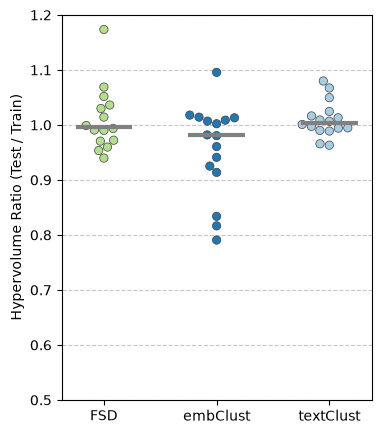

,algorithm,dataset,variable,value
1,FSD,Arabic_Twitter,hv_ratio,0.939754
18,embClust,CrisisLexT26,hv_ratio,0.913735
19,embClust,CrisisLexT6,hv_ratio,0.925180
21,embClust,CrisisMMD,hv_ratio,0.833834
22,embClust,CrisisNLP,hv_ratio,0.790695
27,embClust,MAVEN,hv_ratio,0.941130
28,embClust,Mix_Data,hv_ratio,0.816503


In [132]:
df_results_hv.head()
df = df_results_hv.copy()
df = df.groupby(["algorithm", "dataset"]).agg({
    "hv_train": "median",
    "hv_test": "median",
    "hv_ratio": "median"
}).reset_index()
df = df.melt(id_vars=["algorithm", "dataset"], value_vars=["hv_ratio"])

plt.figure(figsize=(4, 5))
ax = sns.swarmplot(data=df, x="algorithm", y="value", hue="algorithm", 
                   order=order, palette=colors, size=6, linewidth=0.5, legend=False)

# Add vertical mean lines for each algorithm
for i, algorithm in enumerate(order):
    mean_value = df[df["algorithm"] == algorithm]["value"].median()
    print(f"Algorithm: {algorithm}, Mean HV Ratio: {mean_value}")
    ax.hlines(
        y=mean_value,
        xmin=i - 0.25,
        xmax=i + 0.25,
        color="grey",
        linestyle="-",
        linewidth=3,
        alpha=1,
        zorder=10
    )

ax.set_xlabel("")
ax.set_ylabel("Hypervolume Ratio (Test / Train)")
ax.set_ylim(0.5, 1.2)
ax.grid(axis="y", linestyle="--", alpha=0.7)

plt.savefig("figures/hv_ratio_swarmplot.pdf", bbox_inches="tight")
plt.show()

df[df["value"]<0.95]

In [311]:
df.head()

,algorithm,dataset,variable,value
0,FSD,Arabic_7,hv_ratio,1.033179
1,FSD,Arabic_Twitter,hv_ratio,1.047981
2,FSD,CrisisLexT26,hv_ratio,0.893131
3,FSD,CrisisLexT6,hv_ratio,0.977439
4,FSD,CrisisLexT7,hv_ratio,1.008026


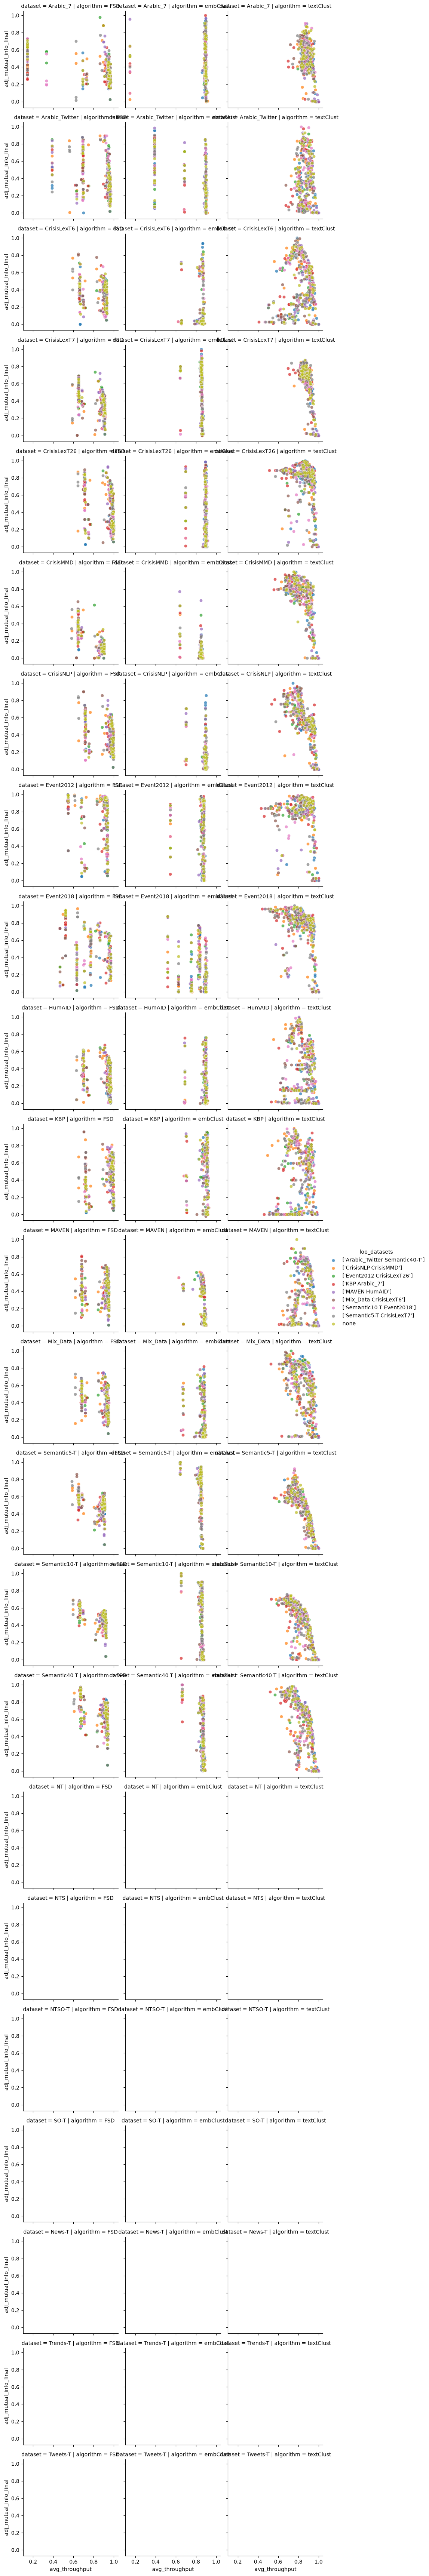

In [39]:
df = smac3_results_eval.copy()
for _, group in df.groupby(["dataset"]):
    df.loc[group.index, ["avg_throughput", "adj_mutual_info_final"]] = normalize(group, columns=["avg_throughput", "adj_mutual_info_final"], use_log=[True, False])

for _, group in df.groupby(["algorithm", "is_test", "dataset"]):
    pareto_indices, pareto_objectives = pareto_optimal_points(
        group,
        objective_columns=["avg_throughput", "adj_mutual_info_final"],
        maximize=[True, True],
    )
    df.loc[group.index, "is_pareto"] = False
    df.loc[pareto_indices, "is_pareto"] = True
    
#df = df[df["is_pareto"] == True]

g = sns.FacetGrid(df, col="algorithm", hue="loo_datasets", row="dataset", sharex=True, sharey=True)
g.map_dataframe(sns.scatterplot, x="avg_throughput", y="adj_mutual_info_final", alpha=0.7, legend=True) \
    .add_legend() 

# Compare the top-k AMIs of each dataset and algorithm

Text(0, 0.5, 'Adjusted Mutual Information')

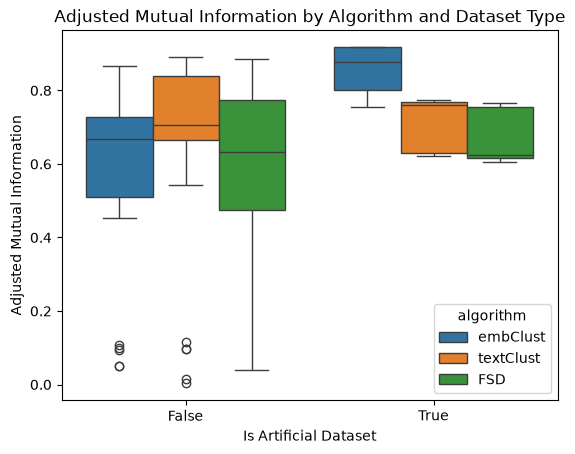

In [10]:
k = 3
df = smac3_results_eval.copy()
df = (
    smac3_results_eval
    .sort_values("adj_mutual_info_final", ascending=False)
    .groupby(["dataset", "algorithm"], sort=False)
    .head(k)
    [["dataset", "algorithm", "avg_throughput", "adj_mutual_info_final"]]
    .reset_index(drop=True)
)

df["is_artificial"] = df["dataset"].str.contains("Semantic")

sns.boxplot(data=df, x="is_artificial", y="adj_mutual_info_final", hue="algorithm", hue_order=color_order) 
plt.title("Adjusted Mutual Information by Algorithm and Dataset Type")
plt.xlabel("Is Artificial Dataset")
plt.ylabel("Adjusted Mutual Information")

# Compare increase in HV, AMI and throughput compared to the default configuration

In [53]:
from moocore._moocore import hypervolume

# Compare HV of default configurations with the HV of the Pareto front of the found configurations
results = []
for (dataset, algorithm), group in smac3_results_eval.groupby(["dataset", "algorithm"]):
    if len(group) == 1 or group[["adj_mutual_info_final", "avg_throughput"]].isna().any().any():
        continue 
    
    # Log normalize throughput
    group.loc[:, ["avg_throughput", "adj_mutual_info_final"]] = normalize(group, columns=["avg_throughput", "adj_mutual_info_final"], use_log=[True, False])[["avg_throughput", "adj_mutual_info_final"]]
    
    default_df = group[group["is_default"]]
    optimized_df = group[~group["is_default"]]
    
    default_values = default_df.loc[:, ["adj_mutual_info_final", "avg_throughput"]].values
    default_hv = hypervolume(default_values, ref=[0.0, 0.0], maximise=[True, True])
    

    # Get the optimize HV
    optimized_values = optimized_df.loc[:, ["adj_mutual_info_final", "avg_throughput"]].values
    optimized_hv = hypervolume(optimized_values, ref=[0, 0], maximise=[True, True])
    
    default_ami = default_df["adj_mutual_info_final"].values[0]
    default_throughput = default_df["avg_throughput"].values[0]
    
    optimized_best_ami = optimized_df["adj_mutual_info_final"].max()
    optimized_best_throughput = optimized_df["avg_throughput"].max()
    
    results.append({
        "dataset": dataset,
        "algorithm": algorithm,
        "default_hv": default_hv,
        "optimized_hv": optimized_hv,
        "hv_difference": optimized_hv - default_hv,
        "hv_ratio": optimized_hv / default_hv if default_hv != 0 else float('inf'),
        "default_ami": default_ami,
        "default_throughput": default_throughput,
        "optimized_best_ami": optimized_best_ami,
        "optimized_best_throughput": optimized_best_throughput,
        "ami_difference": optimized_best_ami - default_ami,
        "throughput_difference": optimized_best_throughput - default_throughput,
        "ami_ratio": optimized_best_ami / default_ami if default_ami != 0 else float('inf'),
        "throughput_ratio": optimized_best_throughput / default_throughput if default_throughput != 0 else float('inf'),
    })
    
default_vs_pareto_df = pd.DataFrame(results)
default_vs_pareto_df.head()

,dataset,algorithm,default_hv,optimized_hv,hv_difference,hv_ratio,default_ami,default_throughput,optimized_best_ami,optimized_best_throughput,ami_difference,throughput_difference,ami_ratio,throughput_ratio
0,Arabic_7,FSD,0.100161,0.986424,0.886263,9.848377,0.676120,0.148141,1.0,1.0,0.323880,0.851859,1.479028,6.750327
1,Arabic_7,embClust,0.056648,0.996312,0.939664,17.587855,0.382017,0.148286,1.0,1.0,0.617983,0.851714,2.617681,6.743740
2,Arabic_7,textClust,0.466610,0.888949,0.422339,1.905123,0.878938,0.530879,1.0,1.0,0.121062,0.469121,1.137737,1.883668
3,Arabic_Twitter,FSD,0.641946,0.992836,0.350890,1.546603,0.901078,0.712420,1.0,1.0,0.098922,0.287580,1.109782,1.403665
4,Arabic_Twitter,embClust,0.250093,0.932532,0.682439,3.728740,0.348796,0.717017,1.0,1.0,0.651204,0.282983,2.867002,1.394667


<Axes: xlabel='metric', ylabel='value'>

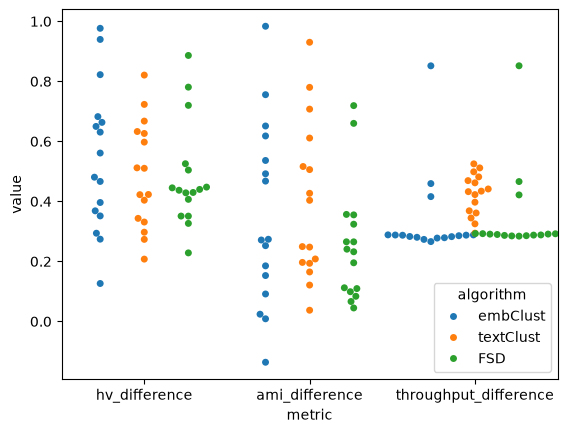

In [56]:
df = default_vs_pareto_df.copy()
df = df.melt(id_vars=["dataset", "algorithm"], 
             value_vars=["hv_difference", "ami_difference", "throughput_difference"], 
             var_name="metric", value_name="value")

sns.swarmplot(data=df, x="metric", y="value", hue="algorithm", hue_order=color_order, dodge=True)

# Full optimization

In [327]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

ROOT = "results/textClust_hpo_results/full_optimization"

def load_final_performance(algorithm: str, seed: int) -> pd.DataFrame:
    df = pd.read_csv(f"{ROOT}/smac3_final_performance/{algorithm}/loo_none_seed_{seed}.csv")
    df["dataset"] = (
        df["dataset"]
        .str.replace("data/textClust_stream_data/raw_data/", "", regex=False)
        .str.replace(".npy", "", regex=False)
        .str.replace(".json", "", regex=False)
    )
    df["is_default"] = False
    return df

algorithms = ["embClust", "textClust", "inc_clust_ray"]
seeds = list(range(1, 11))

results = pd.concat(
    [load_final_performance(algorithm, seed) for algorithm in algorithms for seed in seeds],
    ignore_index=True
)
results["algorithm"] = results["algorithm"].replace({"inc_clust_ray": "FSD"})
def make_config_string(row):
    config_path = row["config"]
    config_id = row["config_id"]
    return f"{config_path}[{config_id}]"

results["config"] = results.apply(make_config_string, axis=1)
results = results.drop(columns=["loo_datasets", "seed", "config_id"])
results_final_performance = results.copy()
results_final_performance.head()


,rand,adj_rand,mutual_info,adj_mutual_info,normalized_mutual_info,homogeneity,completeness,v_measure,fowlkes_mallows,rand_final,...,num_evaluated_points,num_clusters_initial,num_clusters_final,num_clusters_true,avg_throughput,total_time,dataset,config,algorithm,is_default
0,0.811822,0.263769,1.244913,0.523850,0.537074,0.689188,0.439967,0.537074,0.378756,0.783737,...,3022,79.0,73,7,1312.321582,2.302789,Arabic_7,best_config_loo_none_seed_1.json[0],embClust,False
1,0.817101,0.269452,1.354724,0.507853,0.519909,0.749924,0.397875,0.519909,0.382970,0.809332,...,9070,228.0,216,7,1297.659928,6.989505,Arabic_Twitter,best_config_loo_none_seed_1.json[0],embClust,False
2,0.800203,0.222042,1.249184,0.438811,0.451650,0.697183,0.334016,0.451650,0.340050,0.782353,...,60078,1632.0,1586,6,1271.956067,47.232763,CrisisLexT6,best_config_loo_none_seed_1.json[0],embClust,False
3,0.786227,0.491248,0.909453,0.543123,0.555881,0.680378,0.469898,0.555881,0.645400,0.836199,...,1959,44.0,42,7,1347.095081,1.454240,CrisisLexT7,best_config_loo_none_seed_1.json[0],embClust,False
4,0.953525,0.406489,2.660093,0.723654,0.734832,0.818108,0.666942,0.734832,0.431107,0.940637,...,27931,553.0,533,26,928.408332,30.084823,CrisisLexT26,best_config_loo_none_seed_1.json[0],embClust,False


In [328]:
def load_non_preprocessed_performance(algorithm: str, seed: int) -> pd.DataFrame:
    df = pd.read_csv(f"{ROOT}/old_datasets_performance/smac3_best_configs_{algorithm}_best_config_loo_none_seed_{seed}.json_results.csv")
    df["dataset"] = (
        df["dataset"]
        .str.replace("data/textClust_stream_data/raw_data/", "", regex=False)
        .str.replace(".npy", "", regex=False)
        .str.replace(".json", "", regex=False)
    )
    df["is_default"] = False
    return df

results = pd.concat(
    [load_non_preprocessed_performance(algorithm, seed) for algorithm in algorithms for seed in seeds],
    ignore_index=True
)
results["algorithm"] = results["algorithm"].replace({"inc_clust_ray": "FSD"})
results = results.drop(columns=["dataset_name", "config_index"])
results_non_preprocessed_performance = results.copy()
results_non_preprocessed_performance.head()

,rand,adj_rand,mutual_info,adj_mutual_info,normalized_mutual_info,homogeneity,completeness,v_measure,fowlkes_mallows,rand_final,...,num_evaluated_points,num_clusters_initial,num_clusters_final,num_clusters_true,avg_throughput,total_time,dataset,algorithm,config,is_default
0,0.997082,0.765551,5.206155,0.907080,0.926750,0.953937,0.901070,0.926750,0.773986,0.997189,...,41429,979.0,969,419,1316.553729,31.467762,NT,embClust,best_config_loo_none_seed_1.json[0],False
1,0.996381,0.739506,5.111069,0.892124,0.912207,0.966200,0.863929,0.912207,0.758533,0.996643,...,61428,1721.0,1693,439,1402.404590,43.801910,NTS,embClust,best_config_loo_none_seed_1.json[0],False
2,0.592938,-0.000797,2.210056,-0.048735,0.354380,0.250545,0.605194,0.354380,0.003173,0.590820,...,104135,6040.0,6039,10994,1297.100943,80.282880,NTSO-T,embClust,best_config_loo_none_seed_1.json[0],False
3,0.377380,0.000005,1.415132,0.005263,0.249931,0.153352,0.675097,0.249931,0.007858,0.376216,...,123342,3406.0,3405,10573,1310.597498,94.111274,SO-T,embClust,best_config_loo_none_seed_1.json[0],False
4,0.979872,0.404478,3.608518,0.724151,0.776459,0.786162,0.766994,0.776459,0.424063,0.979791,...,11109,359.0,358,152,1466.834747,7.573450,News-T,embClust,best_config_loo_none_seed_1.json[0],False


In [329]:
ROOT = "results/textClust_hpo_results/default_config_performance"

def load_default_performance(algorithm: str) -> pd.DataFrame:
    df = pd.read_csv(f"{ROOT}/smac_hpo_default_{algorithm}.json_results.csv")
    df["dataset"] = (
        df["dataset"]
        .str.replace("data/textClust_stream_data/raw_data/", "", regex=False)
        .str.replace(".npy", "", regex=False)
        .str.replace(".json", "", regex=False)
    )
    df["is_default"] = True
    return df
    
results = pd.concat(
    [load_default_performance(algorithm) for algorithm in algorithms],
    ignore_index=True
)
results["algorithm"] = results["algorithm"].replace({"inc_clust_ray": "FSD"})
results = results.drop(columns=["dataset_name"])
results_default_performance = results.copy()
results_default_performance.head()

,rand,adj_rand,mutual_info,adj_mutual_info,normalized_mutual_info,homogeneity,completeness,v_measure,fowlkes_mallows,rand_final,...,num_evaluated_points,num_clusters_initial,num_clusters_final,num_clusters_true,avg_throughput,total_time,dataset,algorithm,config,is_default
0,0.660349,0.258371,0.805970,0.495556,0.500466,0.446187,0.569780,0.500466,0.492544,0.355823,...,3022,18.0,8,7,2.014298,1500.274692,Arabic_7,embClust,default_embClust.json,True
1,0.622826,0.162621,0.769296,0.434262,0.439815,0.425853,0.454723,0.439815,0.411275,0.340929,...,9070,54.0,8,7,204.183827,44.420756,Arabic_Twitter,embClust,default_embClust.json,True
2,0.696922,0.182142,0.778426,0.371519,0.377831,0.434448,0.334269,0.377831,0.375255,0.590226,...,60078,472.0,97,6,196.597483,305.588857,CrisisLexT6,embClust,default_embClust.json,True
3,0.843528,0.627728,0.976473,0.649745,0.652548,0.730517,0.589617,0.652548,0.743524,0.884295,...,1959,9.0,3,7,200.204618,9.784989,CrisisLexT7,embClust,default_embClust.json,True
4,0.925769,0.368007,2.225938,0.722285,0.725050,0.684584,0.770600,0.725050,0.432854,0.778163,...,27931,85.0,28,26,187.311022,149.115624,CrisisLexT26,embClust,default_embClust.json,True


In [330]:
preprocessed_datasets = [ "NT", "NTS", "NTSO-T", "News-T", "Tweets-T" ]
semantic_datasets = [ "Semantic40-T", "Semantic10-T", "Semantic5-T" ]

print(f"preprocessed_datasets: {preprocessed_datasets}")
print(f"semantic_datasets: {semantic_datasets}")
print(f"real_world_datasets: {results_final_performance[~results_final_performance['dataset'].isin(preprocessed_datasets + semantic_datasets)]['dataset'].unique().tolist()}")

preprocessed_datasets: ['NT', 'NTS', 'NTSO-T', 'News-T', 'Tweets-T']
semantic_datasets: ['Semantic40-T', 'Semantic10-T', 'Semantic5-T']
real_world_datasets: ['Arabic_7', 'Arabic_Twitter', 'CrisisLexT6', 'CrisisLexT7', 'CrisisLexT26', 'CrisisMMD', 'CrisisNLP', 'Event2012', 'Event2018', 'HumAID', 'KBP', 'MAVEN', 'Mix_Data']


In [331]:
# Find mismatch in columns between the three DataFrames
c1 = set(results_final_performance.columns)
c2 = set(results_non_preprocessed_performance.columns)  
c3 = set(results_default_performance.columns)
intersection = c1.intersection(c2).intersection(c3)
print (f"Columns in results_final_performance but not in others: {c1 - intersection}")
print (f"Columns in results_non_preprocessed_performance but not in others: {c2 - intersection}")
print (f"Columns in results_default_performance but not in others: {c3 - intersection}")
assert set(results_final_performance.columns) == set(results_non_preprocessed_performance.columns) == set(results_default_performance.columns), "Column mismatch between the three DataFrames."

results = pd.concat(
    [results_final_performance, results_non_preprocessed_performance, results_default_performance],
    ignore_index=True
)
results["dataset_type"] = "Real-world"
results.loc[results["dataset"].isin(preprocessed_datasets), "dataset_type"] = "Preprocessed"
results.loc[results["dataset"].isin(semantic_datasets), "dataset_type"] = "Artificial"

results_full_performance = results.copy()
results_full_performance.head()

Columns in results_final_performance but not in others: set()
Columns in results_non_preprocessed_performance but not in others: set()
Columns in results_default_performance but not in others: set()


,rand,adj_rand,mutual_info,adj_mutual_info,normalized_mutual_info,homogeneity,completeness,v_measure,fowlkes_mallows,rand_final,...,num_clusters_initial,num_clusters_final,num_clusters_true,avg_throughput,total_time,dataset,config,algorithm,is_default,dataset_type
0,0.811822,0.263769,1.244913,0.523850,0.537074,0.689188,0.439967,0.537074,0.378756,0.783737,...,79.0,73,7,1312.321582,2.302789,Arabic_7,best_config_loo_none_seed_1.json[0],embClust,False,Real-world
1,0.817101,0.269452,1.354724,0.507853,0.519909,0.749924,0.397875,0.519909,0.382970,0.809332,...,228.0,216,7,1297.659928,6.989505,Arabic_Twitter,best_config_loo_none_seed_1.json[0],embClust,False,Real-world
2,0.800203,0.222042,1.249184,0.438811,0.451650,0.697183,0.334016,0.451650,0.340050,0.782353,...,1632.0,1586,6,1271.956067,47.232763,CrisisLexT6,best_config_loo_none_seed_1.json[0],embClust,False,Real-world
3,0.786227,0.491248,0.909453,0.543123,0.555881,0.680378,0.469898,0.555881,0.645400,0.836199,...,44.0,42,7,1347.095081,1.454240,CrisisLexT7,best_config_loo_none_seed_1.json[0],embClust,False,Real-world
4,0.953525,0.406489,2.660093,0.723654,0.734832,0.818108,0.666942,0.734832,0.431107,0.940637,...,553.0,533,26,928.408332,30.084823,CrisisLexT26,best_config_loo_none_seed_1.json[0],embClust,False,Real-world


In [332]:
from moocore._moocore import hypervolume

df = results_full_performance.copy()

# Normalize per dataset
for _, group in df.groupby(["dataset"]):
    df.loc[group.index, ["avg_throughput", "adj_mutual_info_final"]] = normalize(group, columns=["avg_throughput", "adj_mutual_info_final"], use_log=[True, False])[["avg_throughput", "adj_mutual_info_final"]]

result = []
for (is_default, algorithm, dataset, dataset_type), group in df.groupby(["is_default", "algorithm", "dataset", "dataset_type"]):
    if len(group) == 0 or group[["adj_mutual_info_final", "avg_throughput"]].isna().any().any():
        continue 
    
    hv = hypervolume(group[["avg_throughput", "adj_mutual_info_final"]].values, ref=[0.0, 0.0], maximise=[True, True])
    best_ami = group["adj_mutual_info_final"].max()
    best_throughput = group["avg_throughput"].max()
    result.append({
        "is_default": is_default,
        "algorithm": algorithm,
        "dataset": dataset,
        "dataset_type": dataset_type,
        "HV": hv,
        "AMI": best_ami,
        "Throughput": best_throughput
    })

df_result = pd.DataFrame(result)
df_result["config_type"] = df_result["is_default"].map({True: "Default", False: "Optimized"})

pattern_order = ["Optimized", "Default"]

df_result = df_result.melt(id_vars=["config_type", "algorithm", "dataset", "dataset_type"],
                           value_vars=["HV", "AMI", "Throughput"],
                           var_name="metric", value_name="value")


Metric: AMI - Figure saved to figures/boxplot_AMI.pdf


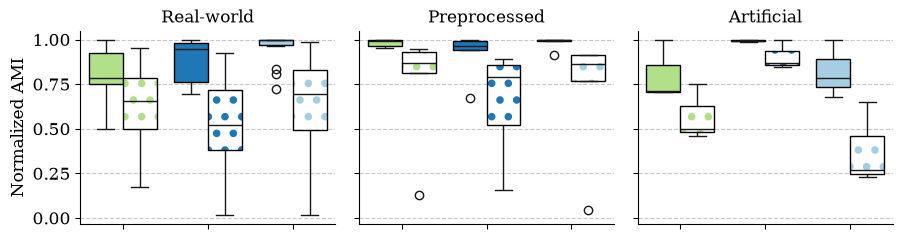

Metric: HV - Figure saved to figures/boxplot_HV.pdf


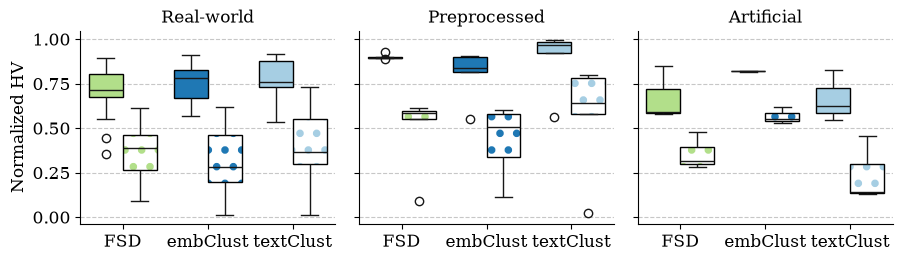

Metric: Throughput - Figure saved to figures/boxplot_Throughput.pdf


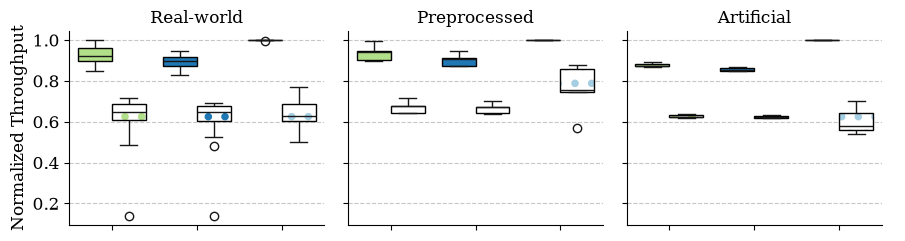

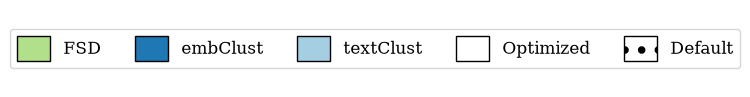

In [333]:
import os 
os.makedirs("figures", exist_ok=True)
# Set font
plt.rcParams.update({'font.family': "serif"})
plt.rcParams.update({'font.size': 12})
for metric, group in df_result.groupby("metric"):
    g = sns.FacetGrid(group, col="dataset_type", sharex=True, sharey=True)
    g.map_dataframe(sns.boxplot, 
                    x="algorithm", y="value", 
                    hue="config_type", hue_order=pattern_order, order=order, palette="dark:#1f77b4",
                    dodge=True, legend=False) \
            .add_legend() \
            .set_titles(col_template="{col_name}", row_template="{row_name}") \
            .set_axis_labels("", f"Normalized {metric}") \
            
    if metric == "HV":        
        g.set_xticklabels(labels=order)
    else:
        g.set_xticklabels(labels="")
                
        
    for ax in g.axes.flatten():
        # Add horizontal grid lines
        for i, box in enumerate(ax.patches):
            algorithm = order[i % len(order)]
            config_type = pattern_order[i // len(order)]
            color = colors[algorithm]
            if config_type == "Optimized":
                box.set_alpha(1.0)
                box.set_facecolor(color)
            else:
                box.set_facecolor("white")
                box.set_hatch('.')
                box.set_hatchcolor(color)
                box.set_hatch_linewidth(3)
            box.set_edgecolor('black')
            box.set_linewidth(1)
        ax.grid(axis='y', linestyle='--', alpha=0.7)
    g.figure.savefig(f"figures/boxplot_{metric}.pdf", dpi=300, bbox_inches='tight')
    print(f"Metric: {metric} - Figure saved to figures/boxplot_{metric}.pdf")
    plt.show()

# Add legend for hatch patterns
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=colors["FSD"], edgecolor='black', label='FSD'),
    Patch(facecolor=colors["embClust"], edgecolor='black', label='embClust'),
    Patch(facecolor=colors["textClust"], edgecolor='black', label='textClust'),
    Patch(facecolor='white', edgecolor='black', hatch='', label='Optimized'),
    Patch(facecolor='white', edgecolor='black', hatch='.', label='Default'),
]

fig, ax = plt.subplots(figsize=(8, 1))
ax.axis('off')

legend = ax.legend(
    handles=legend_elements,
    handlelength=2,
    handleheight=2,
    loc='center',
    ncol=5,
    frameon=True,
)

for handle in legend.legend_handles:
    handle.set_hatch_linewidth(3)

fig.canvas.draw()

bbox = legend.get_window_extent(fig.canvas.get_renderer())
bbox = bbox.transformed(fig.dpi_scale_trans.inverted())
plt.show()
fig.savefig(
    "figures/legend_boxplot.pdf",
    bbox_inches=bbox,
    pad_inches=0.05
)





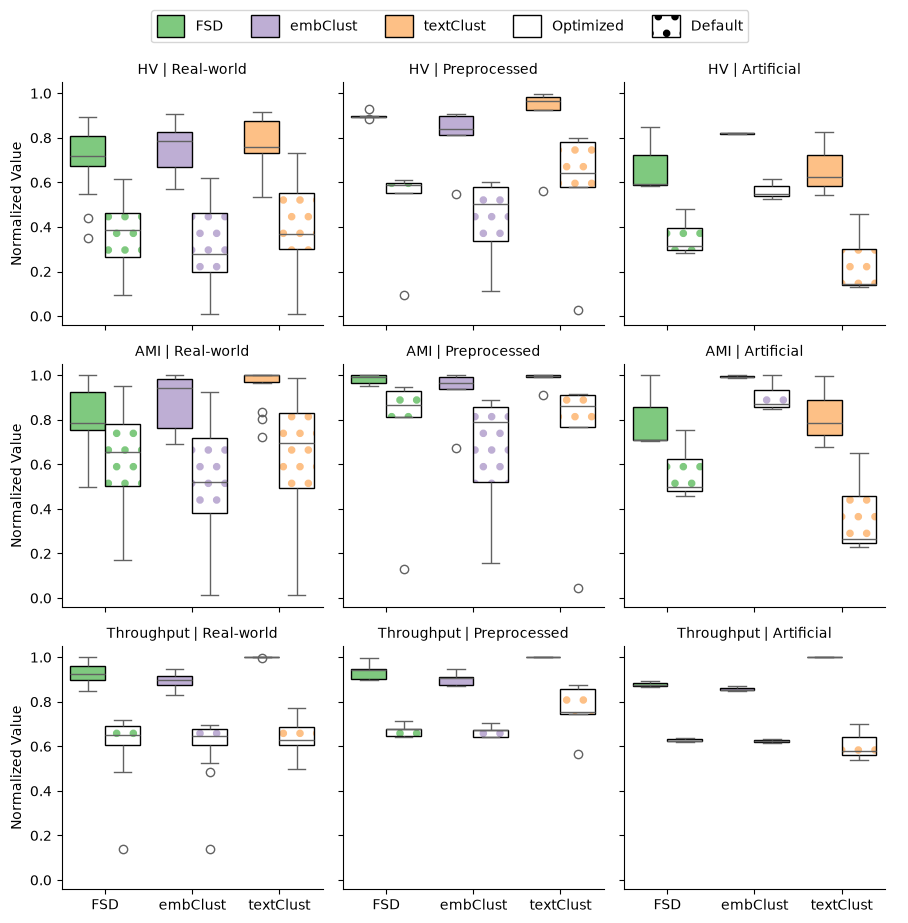

In [135]:

g = sns.FacetGrid(df_result, row="metric", col="dataset_type",  sharex=True, sharey=True) 
g.map_dataframe(sns.boxplot, 
                x="algorithm", y="value", 
                hue="config_type", hue_order=pattern_order, order=hue_order, palette=sns.color_palette("Accent",2),
                dodge=True, legend=False) \
        .add_legend() \
        .set_titles(col_template="{col_name}", row_template="{row_name}") \
        .set_axis_labels("", "Normalized Value") \
    
for ax in g.axes.flatten():
    # Add horizontal grid lines
    for i, box in enumerate(ax.patches):
        algorithm = hue_order[i % len(hue_order)]
        config_type = pattern_order[i // len(hue_order)]
        color = sns.color_palette("Accent")[hue_order.index(algorithm)]
        if config_type == "Optimized":
            box.set_alpha(1.0)
            box.set_facecolor(color)
        else:
            box.set_facecolor("white")
            box.set_hatch('.')
            box.set_hatchcolor(color)
            box.set_hatch_linewidth(3)
        box.set_edgecolor('black')
        box.set_linewidth(1)

# Add legend for hatch patterns
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=sns.color_palette("Accent")[0], edgecolor='black', label='FSD'),
    Patch(facecolor=sns.color_palette("Accent")[1], edgecolor='black', label='embClust'),
    Patch(facecolor=sns.color_palette("Accent")[2], edgecolor='black', label='textClust'),
    Patch(facecolor='white', edgecolor='black', hatch='', label='Optimized'),
    Patch(facecolor='white', edgecolor='black', hatch='.', label='Default'),
]

legend = g.figure.legend(handles=legend_elements, handlelength=2, handleheight=2, loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=5)
for handle in legend.legend_handles:
    handle.set_hatch_linewidth(3)



plt.show()